In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("/content/diamonds.csv")

#**Analysis**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [ ]:
# 1. Drop unnecessary index column
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 2. Drop duplicate rows if any exist
df = df.drop_duplicates()

# 3. Filter out invalid/impossible diamond dimensions (x, y, or z <= 0)
df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]

# 4. Convert ordinal categorical columns to ordered Categorical types
# Fixed clarity list spelling (VVS instead of VSS)
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

df['cut'] = pd.Categorical(df['cut'], categories=cut_order, ordered=True)
df['color'] = pd.Categorical(df['color'], categories=color_order, ordered=True)
df['clarity'] = pd.Categorical(df['clarity'], categories=clarity_order, ordered=True)

# Check the cleaned dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53775 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53775 non-null  float64 
 1   cut      53775 non-null  category
 2   color    53775 non-null  category
 3   clarity  53775 non-null  category
 4   depth    53775 non-null  float64 
 5   table    53775 non-null  float64 
 6   price    53775 non-null  int64   
 7   x        53775 non-null  float64 
 8   y        53775 non-null  float64 
 9   z        53775 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.4 MB


=== NUMERICAL SUMMARY ===
         count         mean          std     min     25%      50%      75%  \
carat  53775.0     0.797536     0.473169    0.20    0.40     0.70     1.04   
depth  53775.0    61.748232     1.429639   43.00   61.00    61.80    62.50   
table  53775.0    57.457806     2.233257   43.00   56.00    57.00    59.00   
price  53775.0  3931.220288  3985.918716  326.00  951.00  2401.00  5324.00   
x      53775.0     5.731579     1.118611    3.73    4.71     5.70     6.54   
y      53775.0     5.734909     1.139451    3.68    4.72     5.71     6.54   
z      53775.0     3.539964     0.702017    1.07    2.91     3.53     4.03   

            max  
carat      5.01  
depth     79.00  
table     95.00  
price  18823.00  
x         10.74  
y         58.90  
z         31.80  

=== CATEGORICAL DISTRIBUTION ===

--- CUT ---
cut
Ideal        21485
Premium      13737
Very Good    12068
Good          4888
Fair          1597
Name: count, dtype: int64

--- COLOR ---
color
G    11254
E

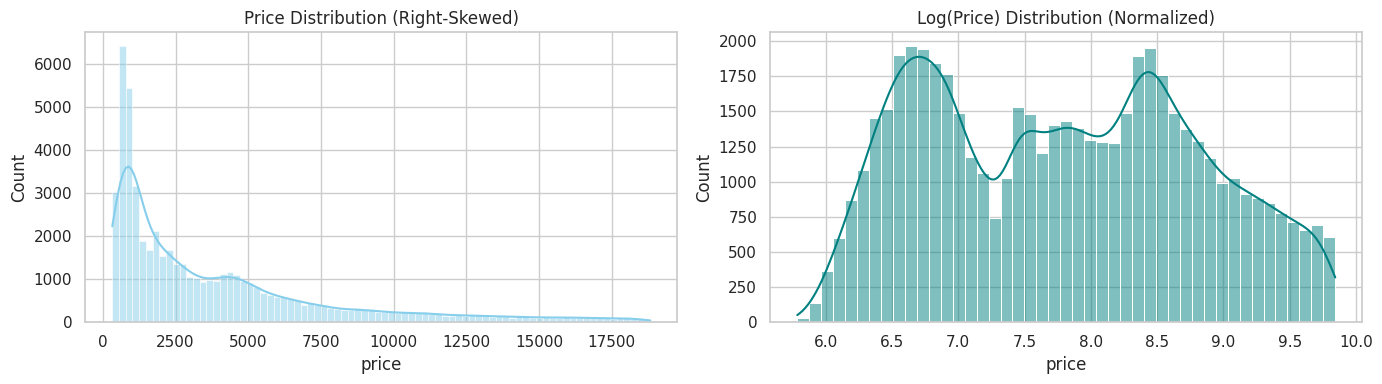

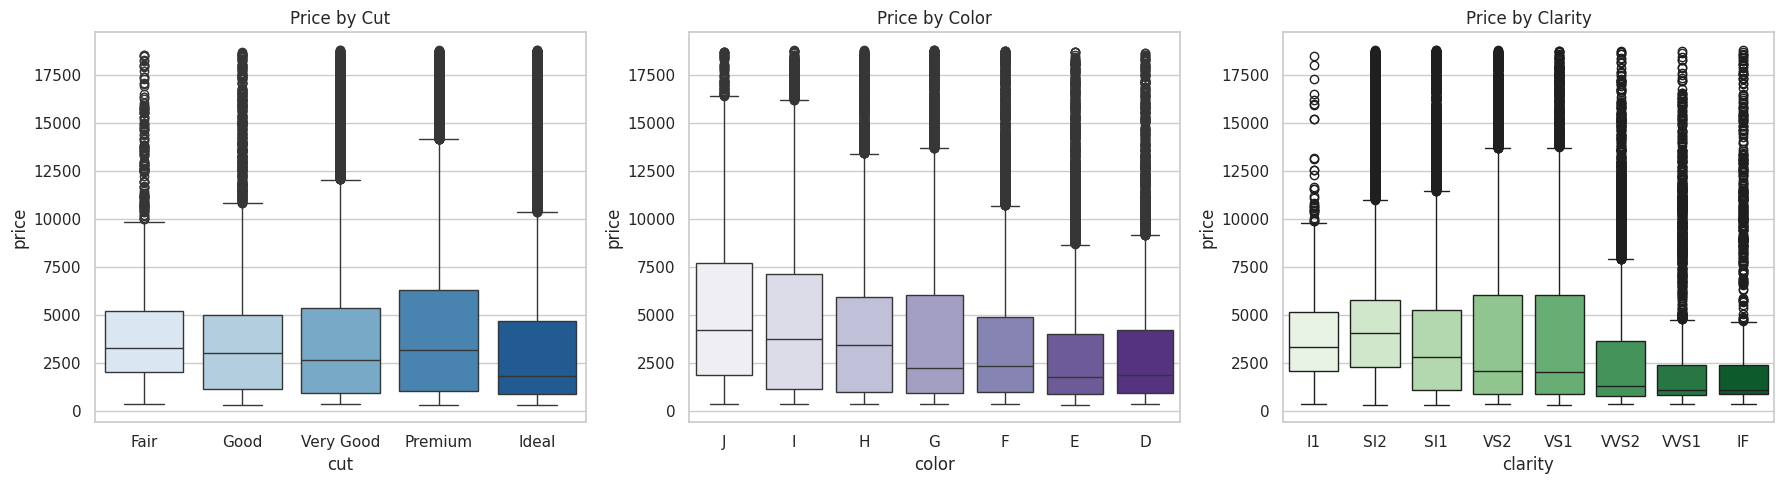

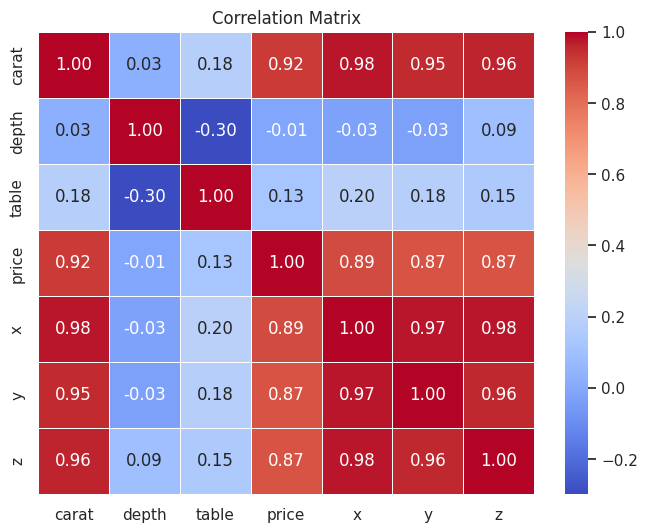

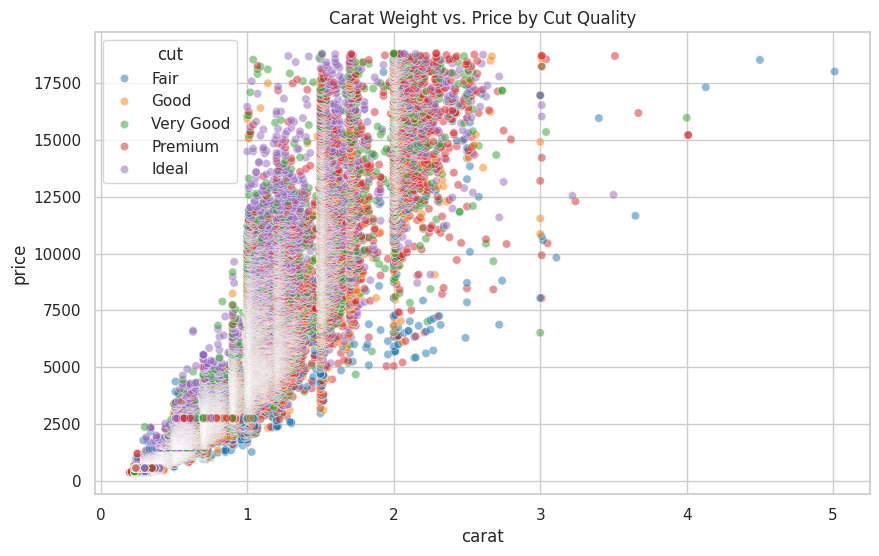

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Overview & Descriptive Statistics
print("=== NUMERICAL SUMMARY ===")
print(df.describe().T)

print("\n=== CATEGORICAL DISTRIBUTION ===")
for col in ['cut', 'color', 'clarity']:
    print(f"\n--- {col.upper()} ---")
    print(df[col].value_counts(dropna=False))

# 2. Target Variable Distribution (Price & Log Price)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Price Distribution (Right-Skewed)')

sns.histplot(np.log(df['price']), kde=True, ax=axes[1], color='teal')
axes[1].set_title('Log(Price) Distribution (Normalized)')
plt.tight_layout()
plt.show()

# 3. Categorical Features vs. Price
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x='cut', y='price', hue='cut', legend=False, ax=axes[0], palette='Blues')
axes[0].set_title('Price by Cut')

sns.boxplot(data=df, x='color', y='price', hue='color', legend=False, ax=axes[1], palette='Purples')
axes[1].set_title('Price by Color')

sns.boxplot(data=df, x='clarity', y='price', hue='clarity', legend=False, ax=axes[2], palette='Greens')
axes[2].set_title('Price by Clarity')
plt.tight_layout()
plt.show()

# 4. Numerical Relationships & Correlation Matrix
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

# 5. Carat vs. Price Scatter Plot (by Cut)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='carat', y='price', hue='cut', alpha=0.5, palette='tab10')
plt.title('Carat Weight vs. Price by Cut Quality')
plt.show()

#**Machine Learning**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# 1. Pipeline setup — remove n_jobs=-1 from RandomForestRegressor to avoid worker locking
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

# 2. Focused hyperparameter grid for Colab
param_grid_rf = {
    'regressor__n_estimators': [100, 200],
    'regressor__max_depth': [15, 25],
    'regressor__min_samples_split': [2, 5]
}

# 3. Setup Grid Search — let n_jobs=-1 handle parallel folds safely here
grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=1
)

# 4. Execute (Will complete in ~1.5 to 2 minutes)
grid_search_rf.fit(X_train, y_train)

# 5. Evaluation
best_rf_model = grid_search_rf.best_estimator_
y_pred_log_rf = best_rf_model.predict(X_test)
y_pred_usd_rf = np.exp(y_pred_log_rf)

r2_rf = r2_score(y_test_usd, y_pred_usd_rf)
mae_rf = mean_absolute_error(y_test_usd, y_pred_usd_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_usd, y_pred_usd_rf))

print("\n=== RANDOM FOREST TUNING RESULTS ===")
print(f"Best Parameters: {grid_search_rf.best_params_}")
print(f"Tuned R² Score:                {r2_rf:.4f}")
print(f"Tuned Mean Absolute Error:     ${mae_rf:.2f}")
print(f"Tuned Root Mean Squared Error: ${rmse_rf:.2f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

=== RANDOM FOREST TUNING RESULTS ===
Best Parameters: {'regressor__max_depth': 25, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 200}
Tuned R² Score:                0.9744
Tuned Mean Absolute Error:     $299.98
Tuned Root Mean Squared Error: $635.70


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Feature Selection & Target Definition
# Log transformation on price handles skewness and stabilizes target variance
X = df.drop(columns=['price'])
y = np.log(df['price'])

categorical_features = ['cut', 'color', 'clarity']
numerical_features = [col for col in X.columns if col not in categorical_features]

# 2. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ]
)

# 4. Model Pipeline (Random Forest Regressor)
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=200,max_depth=25,min_samples_split=2,random_state=42, n_jobs=-1))
])

# 5. Model Training
model_pipeline.fit(X_train, y_train)

# 6. Evaluation (converting log predictions back to original USD scale)
y_pred_log = model_pipeline.predict(X_test)
y_pred_usd = np.exp(y_pred_log)
y_test_usd = np.exp(y_test)

# Calculate Evaluation Metrics
rmse = np.sqrt(mean_squared_error(y_test_usd, y_pred_usd))
mae = mean_absolute_error(y_test_usd, y_pred_usd)
r2 = r2_score(y_test_usd, y_pred_usd)

print(f"=== MODEL PERFORMANCE (USD SCALE) ===")
print(f"R² Score:                 {r2:.4f}")
print(f"Mean Absolute Error:      ${mae:.2f}")
print(f"Root Mean Squared Error:  ${rmse:.2f}")

=== MODEL PERFORMANCE (USD SCALE) ===
R² Score:                 0.9744
Mean Absolute Error:      $299.98
Root Mean Squared Error:  $635.70


=== MODEL PERFORMANCE (USD SCALE) ===
R² Score:                 0.9740
Mean Absolute Error:      $301.30
Root Mean Squared Error:  $640.75

In [ ]:
import pickle
from google.colab import files

# 1. Pickle (serialize) the tuned model pipeline to a file
pickle_filename = 'diamond_price_model.pkl'
with open(pickle_filename, 'wb') as file:
    pickle.dump(best_rf_model, file)

print(f"Model successfully pickled to {pickle_filename}")

# 2. Automatically download the file to your computer
files.download(pickle_filename)

Model successfully pickled to diamond_price_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#**ANN**

In [ ]:
#pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Preprocess data (One-Hot Encode categoricals & Scale features)
X = df.drop(columns=['price'])
y = np.log(df['price'])

# Convert categorical columns to dummy variables (numeric)
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize numerical features for proper neural network convergence
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Define the Optuna Objective Function for Regression
def objective(trial):
    hidden_units = trial.suggest_int("hidden_units", 64, 512)
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    optimizer_name = trial.suggest_categorical("optimizer", ['adam', 'sgd'])

    model = keras.Sequential([
        # Input shape dynamically matches preprocessed features count
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(hidden_units, activation='relu'),
        layers.Dropout(dropout_rate),
        layers.Dense(1)  # Single continuous output for regression
    ])

    if optimizer_name == 'sgd':
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    # Use Mean Squared Error (MSE) loss and RMSE metric for regression
    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error',
        metrics=[keras.metrics.RootMeanSquaredError(name='rmse')]
    )

    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_test_scaled, y_test),
        batch_size=128,
        epochs=10,
        verbose=0
    )

    # Minimize validation RMSE score
    return min(history.history['val_rmse'])

# 3. Run Optimization (Direction set to 'minimize' for RMSE error)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)

print("Best Trial:")
trial = study.best_trial
print(f"  Validation RMSE: {trial.value:.4f}")
print("  Params: ")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

[I 2026-11-05 09:03:21,119] A new study created in memory with name: no-name-3bc07fff-68a2-4cf4-9a54-e34dd80965ac
[I 2026-11-05 09:03:34,477] Trial 0 finished with value: 0.1838388890028 and parameters: {'hidden_units': 423, 'dropout_rate': 0.2910171494628755, 'learning_rate': 0.00021547431844081127, 'optimizer': 'adam'}. Best is trial 0 with value: 0.1838388890028.
[I 2026-11-05 09:03:49,842] Trial 1 finished with value: 0.13773702085018158 and parameters: {'hidden_units': 503, 'dropout_rate': 0.14714494994487884, 'learning_rate': 0.0011899304075763983, 'optimizer': 'adam'}. Best is trial 1 with value: 0.13773702085018158.
[I 2026-11-05 09:03:59,726] Trial 2 finished with value: 0.23835352063179016 and parameters: {'hidden_units': 159, 'dropout_rate': 0.356488369403423, 'learning_rate': 0.0024200083016350875, 'optimizer': 'sgd'}. Best is trial 1 with value: 0.13773702085018158.
[I 2026-11-05 09:04:09,314] Trial 3 finished with value: 0.2293887883424759 and parameters: {'hidden_units':

Best Trial:
  Validation RMSE: 0.1355
  Params: 
    hidden_units: 417
    dropout_rate: 0.10149062437326492
    learning_rate: 0.0005819396706451715
    optimizer: adam


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Feature Preprocessing
X = df.drop(columns=['price'])
y = np.log(df['price'])

# Convert categorical columns to dummy numeric features
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Build ANN Model with Best Parameters
best_params = {
    'hidden_units': 417,
    'dropout_rate': 0.10149,
    'learning_rate': 0.0005819,
    'optimizer': 'adam'
}

model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(best_params['hidden_units'], activation='relu'),
    layers.Dropout(best_params['dropout_rate']),
    layers.Dense(1)  # Single continuous output for regression
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_params['learning_rate']),
    loss='mean_squared_error',
    metrics=[keras.metrics.RootMeanSquaredError(name='rmse')]
)

# 3. Train Model
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=50,
    batch_size=128,
    verbose=1
)

# 4. Evaluate Model in USD Scale
y_pred_log = model.predict(X_test_scaled).flatten()

# Convert log scale predictions back to USD
y_pred_usd = np.exp(y_pred_log)
y_test_usd = np.exp(y_test)

r2 = r2_score(y_test_usd, y_pred_usd)
mae = mean_absolute_error(y_test_usd, y_pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, y_pred_usd))

print("\n=== ANN MODEL PERFORMANCE (USD SCALE) ===")
print(f"R² Score:                 {r2:.4f}")
print(f"Mean Absolute Error:      ${mae:.2f}")
print(f"Root Mean Squared Error:  ${rmse:.2f}")

Epoch 1/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 7.5889 - rmse: 2.7548 - val_loss: 0.2864 - val_rmse: 0.5352
Epoch 2/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3274 - rmse: 0.5722 - val_loss: 0.0938 - val_rmse: 0.3063
Epoch 3/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1923 - rmse: 0.4385 - val_loss: 0.0393 - val_rmse: 0.1982
Epoch 4/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1459 - rmse: 0.3820 - val_loss: 0.0485 - val_rmse: 0.2202
Epoch 5/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1222 - rmse: 0.3495 - val_loss: 0.0243 - val_rmse: 0.1560
Epoch 6/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1065 - rmse: 0.3263 - val_loss: 0.0238 - val_rmse: 0.1544
Epoch 7/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1008 - rmse: 0.3175 - val_loss: 0.0204 - val_rmse: 0.1429
Epoch 8/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0932 - rmse: 0.3053 - val_loss: 0.0200 - val_rmse: 0.1413
Epoch 9/50
337/337 ━━━━━━━━━━━━━━━━━━━━ 

#**Data Preprocessing**

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ============================================================
# 1. FEATURE SELECTION AND TARGET
# ============================================================

X = df.drop(columns=['price']).copy()

if (df['price'] <= 0).any():
    raise ValueError("Price must be positive for log transformation.")

y = np.log(df['price'].astype(float))

# ============================================================
# 2. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First split: 80% development, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED
)

# Second split: 64% train, 16% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=SEED
)

print("========== DATASET SPLIT ==========")
print(f"Training:   {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Testing:    {len(X_test)}")

# ============================================================
# 3. DEFINE FEATURE TYPES
# ============================================================

categorical_features = ['cut', 'color', 'clarity']

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

# ============================================================
# 4. RANDOM FOREST PREPROCESSING PIPELINE
# ============================================================

rf_preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),

        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore'
        ), categorical_features)
    ]
)

# ============================================================
# 5. ANN ONE-HOT ENCODING
# ============================================================

X_train_ann = pd.get_dummies(
    X_train,
    drop_first=True,
    dtype=float
)

X_val_ann = pd.get_dummies(
    X_val,
    drop_first=True,
    dtype=float
)

X_test_ann = pd.get_dummies(
    X_test,
    drop_first=True,
    dtype=float
)

# Align validation and test columns with training
X_val_ann = X_val_ann.reindex(
    columns=X_train_ann.columns,
    fill_value=0
)

X_test_ann = X_test_ann.reindex(
    columns=X_train_ann.columns,
    fill_value=0
)

# ============================================================
# 6. ANN FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_ann)

X_val_scaled = scaler.transform(X_val_ann)

X_test_scaled = scaler.transform(X_test_ann)

# Convert targets to NumPy arrays for TensorFlow
y_train_ann = y_train.to_numpy(dtype=np.float32)
y_val_ann = y_val.to_numpy(dtype=np.float32)
y_test_ann = y_test.to_numpy(dtype=np.float32)

# Actual prices in USD for final evaluation
y_test_usd = np.exp(y_test.to_numpy())

print("\nPreprocessing completed successfully.")
print("ANN input features:", X_train_scaled.shape[1])


========== DATASET SPLIT ==========
Training:   34416
Validation: 8604
Testing:    10755

Preprocessing completed successfully.
ANN input features: 23


In [ ]:
!pip install tqdm tqdm-joblib

#**Random Forest Hyperparameter tunning**

In [ ]:
# ============================================================
# RANDOM FOREST - FAST HYPERPARAMETER TUNING
# ============================================================

import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

from tqdm.auto import tqdm
from tqdm_joblib import tqdm_joblib

# ------------------------------------------------------------
# 1. Create Random Forest pipeline
# ------------------------------------------------------------

rf_pipeline = Pipeline(steps=[
    ('preprocessor', rf_preprocessor),

    ('regressor', RandomForestRegressor(
        random_state=SEED,
        n_jobs=1
    ))
])

# ------------------------------------------------------------
# 2. Define a smaller hyperparameter search space
# ------------------------------------------------------------

param_distributions_rf = {
    'regressor__n_estimators': [80, 120, 160],

    'regressor__max_depth': [12, 20, None],

    'regressor__min_samples_split': [2, 5],

    'regressor__min_samples_leaf': [1, 2],

    'regressor__max_features': ['sqrt', 1.0]
}

# ------------------------------------------------------------
# 3. Configure Randomized Search
# ------------------------------------------------------------

N_ITER = 12
CV_FOLDS = 2

total_fits = N_ITER * CV_FOLDS

print("Total parameter combinations to test:", N_ITER)
print("Total model fits:", total_fits)

random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,

    param_distributions=param_distributions_rf,

    n_iter=N_ITER,

    scoring='neg_root_mean_squared_error',

    cv=CV_FOLDS,

    random_state=SEED,

    n_jobs=-1,

    verbose=0,

    refit=True
)

# ------------------------------------------------------------
# 4. Fit with progress bar
# ------------------------------------------------------------

with tqdm_joblib(
    tqdm(
        total=total_fits,
        desc="Random Forest Tuning",
        unit="fit"
    )
):
    random_search_rf.fit(X_train, y_train)

# ------------------------------------------------------------
# 5. Display best results
# ------------------------------------------------------------

print("\nBest Hyperparameters:")
print(random_search_rf.best_params_)

print("\nBest Cross-Validation RMSE (log scale):")
print(-random_search_rf.best_score_)

Total parameter combinations to test: 12
Total model fits: 24


Random Forest Tuning:   0%|          | 0/24 [00:00<?, ?fit/s]

  0%|          | 0/24 [00:00<?, ?it/s]


Best Hyperparameters:
{'regressor__n_estimators': 160, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 1.0, 'regressor__max_depth': None}

Best Cross-Validation RMSE (log scale):
0.11490863916741961


#**Building Random Forest Model**

In [ ]:
best_rf_model = random_search_rf.best_estimator_

y_pred_log_rf = best_rf_model.predict(X_test)

y_pred_usd_rf = np.exp(y_pred_log_rf)

y_test_usd = np.exp(y_test.to_numpy())

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2_rf = r2_score(y_test_usd, y_pred_usd_rf)
mae_rf = mean_absolute_error(y_test_usd, y_pred_usd_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_usd, y_pred_usd_rf))

print("Random Forest Results")
print("---------------------")
print(f"R2 Score: {r2_rf:.4f}")
print(f"MAE: ${mae_rf:.2f}")
print(f"RMSE: ${rmse_rf:.2f}")

Random Forest Results
---------------------
R2 Score: 0.9709
MAE: $310.16
RMSE: $678.36


In [ ]:
# ============================================================
# RANDOM FOREST - FINAL MODEL BUILDING AND EVALUATION
# ============================================================

import numpy as np

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# 1. GET BEST RANDOM FOREST MODEL
# ============================================================

best_rf_model = random_search_rf.best_estimator_

# ============================================================
# 2. PREDICTION ON TEST DATA
# ============================================================

y_pred_log_rf = best_rf_model.predict(X_test)

# Convert log predictions back to USD
y_pred_usd_rf = np.exp(y_pred_log_rf)

# Actual prices in USD
y_test_usd = np.exp(y_test.to_numpy())

# ============================================================
# 3. EVALUATION
# ============================================================

r2_rf = r2_score(y_test_usd, y_pred_usd_rf)

mae_rf = mean_absolute_error(
    y_test_usd,
    y_pred_usd_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test_usd,
        y_pred_usd_rf
    )
)

# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("\n========== RANDOM FOREST PERFORMANCE (USD) ==========")

print(f"R² Score:                 {r2_rf:.4f}")
print(f"Mean Absolute Error:      ${mae_rf:.2f}")
print(f"Root Mean Squared Error:  ${rmse_rf:.2f}")

print("\nBest Hyperparameters:")
print(random_search_rf.best_params_)


========== RANDOM FOREST PERFORMANCE (USD) ==========
R² Score:                 0.9709
Mean Absolute Error:      $310.16
Root Mean Squared Error:  $678.36

Best Hyperparameters:
{'regressor__n_estimators': 160, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 1.0, 'regressor__max_depth': None}


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


#**Hyperparameter Tuning for ANN**

In [ ]:
# ============================================================
# ANN - HYPERPARAMETER TUNING USING OPTUNA
# ============================================================

import optuna
import tensorflow as tf
import gc

from tensorflow import keras
from tensorflow.keras import layers

# ============================================================
# 1. ANN MODEL BUILDING FUNCTION
# ============================================================

def build_ann(trial):

    # Tune number of hidden layers
    n_hidden_layers = trial.suggest_int(
        'n_hidden_layers', 1, 4
    )

    # Tune neurons in each hidden layer
    hidden_units = trial.suggest_int(
        'hidden_units', 64, 512, step=32
    )

    # Tune activation function
    activation = trial.suggest_categorical(
        'activation', ['relu', 'tanh', 'elu']
    )

    # Tune dropout
    dropout_rate = trial.suggest_float(
        'dropout_rate', 0.1, 0.5
    )

    # Tune learning rate
    learning_rate = trial.suggest_float(
        'learning_rate', 1e-4, 1e-2, log=True
    )

    # Tune optimizer
    optimizer_name = trial.suggest_categorical(
        'optimizer', ['adam', 'sgd']
    )

    # ========================================================
    # BUILD DYNAMIC ANN ARCHITECTURE
    # ========================================================

    model = keras.Sequential()

    model.add(
        layers.Input(shape=(X_train_scaled.shape[1],))
    )

    for i in range(n_hidden_layers):

        model.add(
            layers.Dense(
                hidden_units,
                activation=activation
            )
        )

        model.add(
            layers.Dropout(dropout_rate)
        )

    # Output layer for regression
    model.add(layers.Dense(1))

    # ========================================================
    # OPTIMIZER SELECTION
    # ========================================================

    if optimizer_name == 'adam':

        optimizer = keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    else:

        optimizer = keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    # ========================================================
    # COMPILE MODEL
    # ========================================================

    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error',
        metrics=[
            keras.metrics.RootMeanSquaredError(name='rmse')
        ]
    )

    return model


# ============================================================
# 2. OPTUNA OBJECTIVE FUNCTION
# ============================================================

def objective(trial):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_ann(trial)

    early_stopping = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=0
    )

    history = model.fit(
        X_train_scaled,
        y_train_ann,

        validation_data=(
            X_val_scaled,
            y_val_ann
        ),

        epochs=100,
        batch_size=128,

        callbacks=[early_stopping],

        verbose=0
    )

    # Return lowest validation RMSE
    best_val_rmse = min(
        history.history['val_rmse']
    )

    del model
    gc.collect()

    return best_val_rmse


# ============================================================
# 3. RUN OPTUNA OPTIMIZATION WITH PROGRESS BAR
# ============================================================

study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True,
    gc_after_trial=True
)


# ============================================================
# 4. DISPLAY BEST PARAMETERS
# ============================================================

best_params = study.best_trial.params

print("\n========== ANN BEST HYPERPARAMETERS ==========")

print(
    f"Best Validation RMSE (log scale): "
    f"{study.best_value:.5f}"
)

for key, value in best_params.items():
    print(f"{key}: {value}")

[I 2026-11-05 10:41:19,639] A new study created in memory with name: no-name-3d86e054-4918-48be-bb17-237f657c5376


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-05 10:43:52,617] Trial 0 finished with value: 0.15532104671001434 and parameters: {'n_hidden_layers': 2, 'hidden_units': 512, 'activation': 'relu', 'dropout_rate': 0.16239780813448107, 'learning_rate': 0.00013066739238053285, 'optimizer': 'adam'}. Best is trial 0 with value: 0.15532104671001434.
[I 2026-11-05 10:45:25,360] Trial 1 finished with value: 0.5386987328529358 and parameters: {'n_hidden_layers': 3, 'hidden_units': 64, 'activation': 'relu', 'dropout_rate': 0.17272998688284025, 'learning_rate': 0.00023270677083837802, 'optimizer': 'sgd'}. Best is trial 0 with value: 0.15532104671001434.
[I 2026-11-05 10:46:39,060] Trial 2 finished with value: 0.1465570628643036 and parameters: {'n_hidden_layers': 2, 'hidden_units': 192, 'activation': 'relu', 'dropout_rate': 0.2465447373174767, 'learning_rate': 0.000816845589476017, 'optimizer': 'adam'}. Best is trial 2 with value: 0.1465570628643036.
[I 2026-11-05 10:47:52,657] Trial 3 finished with value: 0.1372695118188858 and para

#**ANN Model Building**

In [ ]:

# ============================================================
# 1. BUILD FINAL ANN MODEL
# ============================================================

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = keras.Sequential()

model.add(
    layers.Input(shape=(X_train_scaled.shape[1],))
)

# Add the optimized number of hidden layers
for i in range(best_params['n_hidden_layers']):

    model.add(
        layers.Dense(
            best_params['hidden_units'],
            activation=best_params['activation']
        )
    )

    model.add(
        layers.Dropout(best_params['dropout_rate'])
    )

# Output layer
model.add(layers.Dense(1))

# ============================================================
# 2. SELECT OPTIMIZED OPTIMIZER
# ============================================================

if best_params['optimizer'] == 'adam':

    optimizer = keras.optimizers.Adam(
        learning_rate=best_params['learning_rate']
    )

else:

    optimizer = keras.optimizers.SGD(
        learning_rate=best_params['learning_rate']
    )

# ============================================================
# 3. COMPILE MODEL
# ============================================================

model.compile(
    optimizer=optimizer,
    loss='mean_squared_error',
    metrics=[
        keras.metrics.RootMeanSquaredError(name='rmse')
    ]
)

# Display ANN architecture
model.summary()

# ============================================================
# 4. EARLY STOPPING
# ============================================================

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

# ============================================================
# 5. TRAIN FINAL ANN MODEL
# ============================================================

history = model.fit(
    X_train_scaled,
    y_train_ann,

    validation_data=(
        X_val_scaled,
        y_val_ann
    ),

    epochs=200,
    batch_size=128,

    callbacks=[early_stopping],

    verbose=1
)

# ============================================================
# 6. PREDICTIONS ON TEST DATA
# ============================================================

y_pred_log_ann = model.predict(
    X_test_scaled,
    verbose=0
).flatten()

# Convert log predictions back to USD
y_pred_usd_ann = np.exp(y_pred_log_ann)

# ============================================================
# 7. MODEL EVALUATION
# ============================================================

r2_ann = r2_score(
    y_test_usd,
    y_pred_usd_ann
)

mae_ann = mean_absolute_error(
    y_test_usd,
    y_pred_usd_ann
)

rmse_ann = np.sqrt(
    mean_squared_error(
        y_test_usd,
        y_pred_usd_ann
    )
)

print("\n========== ANN MODEL PERFORMANCE (USD) ==========")

print(f"R² Score:                 {r2_ann:.4f}")
print(f"Mean Absolute Error:      ${mae_ann:.2f}")
print(f"Root Mean Squared Error:  ${rmse_ann:.2f}")

print("\n========== TRAINING INFORMATION ==========")

print(f"Best Epoch: {np.argmin(history.history['val_loss']) + 1}")
print(f"Total Epochs: {len(history.history['loss'])}")

print("\n========== SELECTED ANN ARCHITECTURE ==========")

print(f"Hidden Layers: {best_params['n_hidden_layers']}")
print(f"Neurons per Layer: {best_params['hidden_units']}")
print(f"Activation: {best_params['activation']}")
print(f"Dropout: {best_params['dropout_rate']}")
print(f"Optimizer: {best_params['optimizer']}")
print(f"Learning Rate: {best_params['learning_rate']}")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,761 (22.50 KB)

 Trainable params: 5,761 (22.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 2.4759 - rmse: 1.5735 - val_loss: 0.0704 - val_rmse: 0.2653
Epoch 2/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3905 - rmse: 0.6249 - val_loss: 0.0533 - val_rmse: 0.2309
Epoch 3/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3251 - rmse: 0.5702 - val_loss: 0.0504 - val_rmse: 0.2245
Epoch 4/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2945 - rmse: 0.5427 - val_loss: 0.0450 - val_rmse: 0.2122
Epoch 5/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2577 - rmse: 0.5076 - val_loss: 0.0502 - val_rmse: 0.2241
Epoch 6/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2436 - rmse: 0.4936 - val_loss: 0.0369 - val_rmse: 0.1920
Epoch 7/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2198 - rmse: 0.4689 - val_loss: 0.0354 - val_rmse: 0.1881
Epoch 8/200
269/269 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2026 - rmse: 0.4502 - val_loss: 0.0407 - val_rmse: 0.2017
Epoch 9/200
269/269 ━━━━━━━━━━━━

#**Model Comparasion**

In [ ]:

# ============================================================
# COMPARE RANDOM FOREST AND ANN
# ============================================================

comparison = pd.DataFrame({
    'Model': ['Random Forest', 'ANN'],

    'R2 Score': [
        r2_rf,
        r2_ann
    ],

    'MAE (USD)': [
        mae_rf,
        mae_ann
    ],

    'RMSE (USD)': [
        rmse_rf,
        rmse_ann
    ]
})

print("\n========== FINAL MODEL COMPARISON ==========")

print(comparison.to_string(index=False))

# Determine the winner using RMSE
if rmse_rf < rmse_ann:

    print("\nWinner: Random Forest")

elif rmse_ann < rmse_rf:

    print("\nWinner: ANN")

else:

    print("\nBoth models have equal RMSE.")



========== FINAL MODEL COMPARISON ==========
        Model  R2 Score  MAE (USD)  RMSE (USD)
Random Forest  0.970881 310.155177  678.355873
          ANN  0.973891 340.314909  642.342124

Winner: ANN
